# NetGuard AI
## 02 — Exploratory Data Analysis and Class Analysis

### Objective

The objective of this notebook is to explore the cleaned network
traffic dataset and understand the differences between BENIGN and
DDoS traffic.

We will investigate:

1. Class distribution
2. Feature distributions
3. Statistical differences between classes
4. Outliers and skewness
5. Correlation between important features
6. Differences in network traffic behaviour between BENIGN and DDoS

This analysis will help us understand the dataset before performing
statistical feature analysis and feature selection.

In [1]:
# Import libraries
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load the cleaned dataset
df = pd.read_csv("netguard_cleaned.csv")

print("Dataset loaded successfully.")
print("Shape:", df.shape)

Dataset loaded successfully.
Shape: (223082, 79)


In [ ]:
target = "Label"

X = df.drop(columns=[target])
y = df[target]

print("Number of features:", X.shape[1])
print("Number of records:", X.shape[0])
print("Target:", target)

In [3]:
# Separate features and target
target = "Label"

X = df.drop(columns=[target])
y = df[target]

print("Number of features:", X.shape[1])
print("Number of records:", X.shape[0])
print("Target:", target)

Number of features: 78
Number of records: 223082
Target: Label


In [4]:
# Class distribution
class_counts = y.value_counts()

print(class_counts)

Label
DDoS      128014
BENIGN     95068
Name: count, dtype: int64


In [7]:
class_percentages = y.value_counts(normalize=True) * 100

print(class_percentages.round(2))

Label
DDoS      57.38
BENIGN    42.62
Name: proportion, dtype: float64


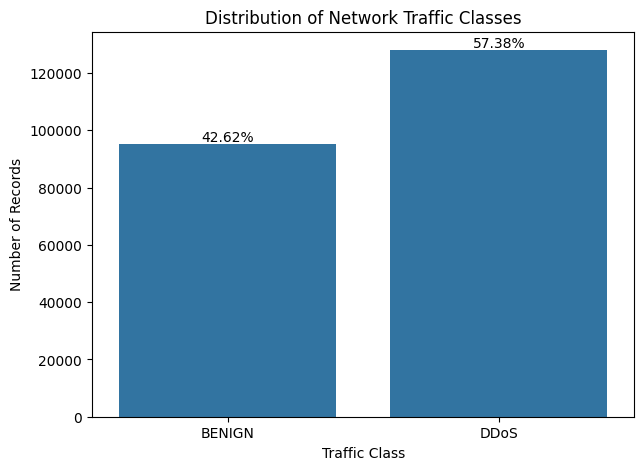

In [16]:
# Visualization
plt.figure(figsize=(7, 5))

ax=sns.countplot(data=df, x="Label")

plt.title("Distribution of Network Traffic Classes")
plt.xlabel("Traffic Class")
plt.ylabel("Number of Records")
plt.bar_label(ax.containers[0],[f"{(i/len(df))*100:.2f}%" for i in df['Label'].value_counts()[::-1]])

plt.show()

In [20]:
numeric_columns = df.select_dtypes(include=np.number).columns

class_means = df.groupby("Label")[numeric_columns].mean().T

class_means.head(20)

Label,BENIGN,DDoS
Destination Port,2.096121e+04,8.122751e+01
Flow Duration,1.573290e+07,1.695716e+07
Total Fwd Packets,5.489029e+00,4.472683e+00
Total Backward Packets,6.438128e+00,3.256081e+00
Total Length of Fwd Packets,2.185761e+03,3.191057e+01
Total Length of Bwd Packets,4.220149e+03,7.374351e+03
Fwd Packet Length Max,1.257983e+03,1.489854e+01
Fwd Packet Length Min,6.253865e+01,2.184652e+00
Fwd Packet Length Mean,3.806901e+02,7.401404e+00
Fwd Packet Length Std,5.025948e+02,5.722567e+00


In [21]:
mean_difference = (
    class_means["DDoS"] - class_means["BENIGN"]
).sort_values(key=abs, ascending=False)

mean_difference.head(20)

Bwd IAT Total            -1.454652e+07
Bwd IAT Max              -9.814419e+06
Fwd IAT Max               5.582413e+06
Flow IAT Max              5.135577e+06
Idle Max                  4.983755e+06
Idle Mean                 3.616298e+06
Packet Length Variance    3.366299e+06
Bwd IAT Std              -3.310547e+06
Idle Min                  2.274569e+06
Fwd IAT Total             2.201053e+06
Fwd IAT Std               2.059400e+06
Bwd IAT Mean             -1.987795e+06
Idle Std                  1.940386e+06
Flow IAT Std              1.907883e+06
Flow Duration             1.224261e+06
Flow Bytes/s             -1.154903e+06
Flow IAT Mean             6.623110e+05
Bwd IAT Min              -5.359481e+05
Fwd IAT Min              -4.861979e+05
Fwd IAT Mean              1.974494e+05
dtype: float64

This tells us which features have the largest raw difference in mean between BENIGN and DDoS traffic.

Important

Don't interpret this as final feature importance.

A feature can have a large mean difference but still have:

high variance,
strong outliers,
overlapping class distributions.

That's why we will perform proper statistical feature analysis .

In [22]:
features_to_plot = [
    "Flow Duration",
    "Total Fwd Packets",
    "Total Backward Packets",
    "Total Length of Fwd Packets",
    "Total Length of Bwd Packets"
]

In [23]:
features_to_plot = [
    feature for feature in features_to_plot
    if feature in df.columns
]

print(features_to_plot)

['Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets']


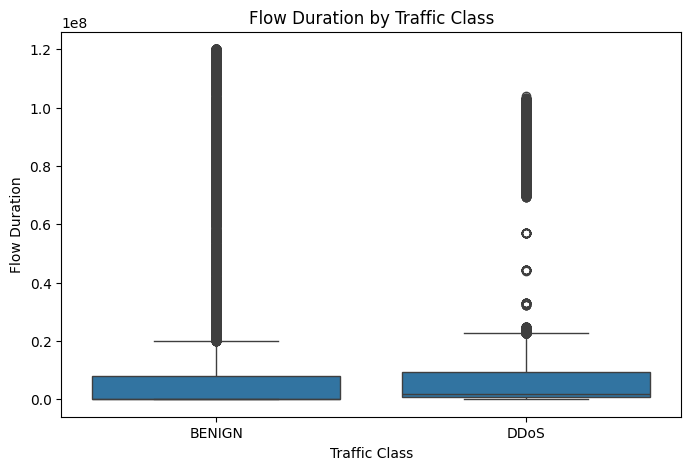

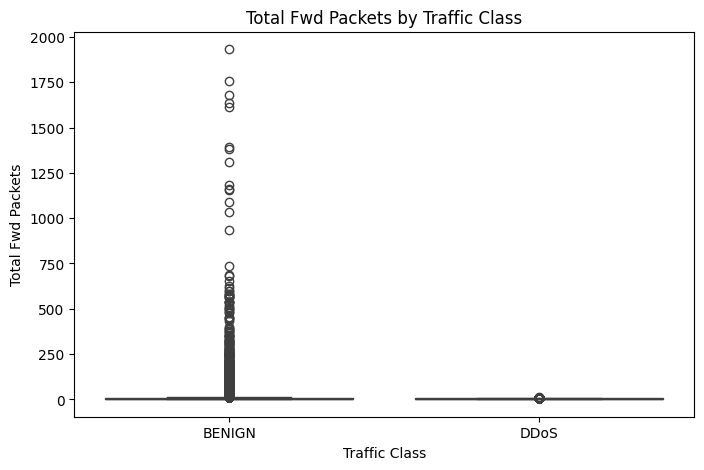

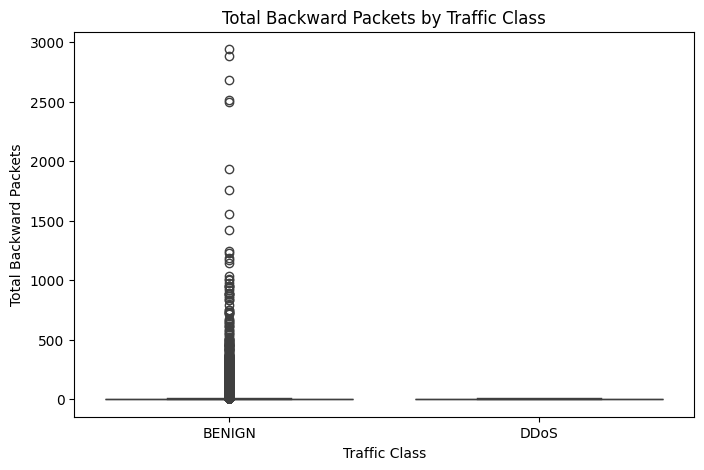

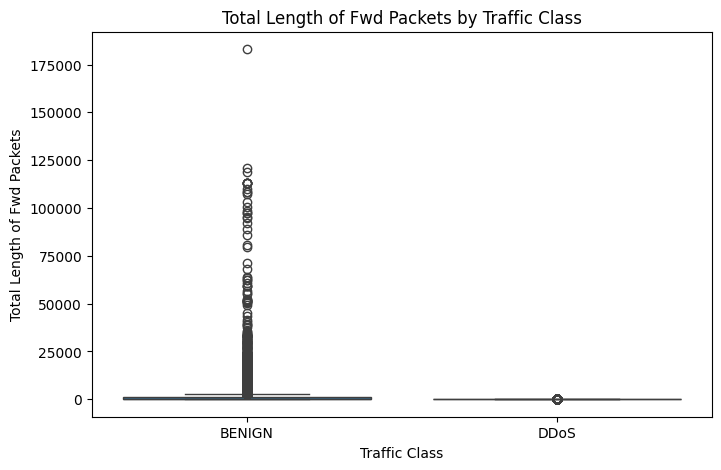

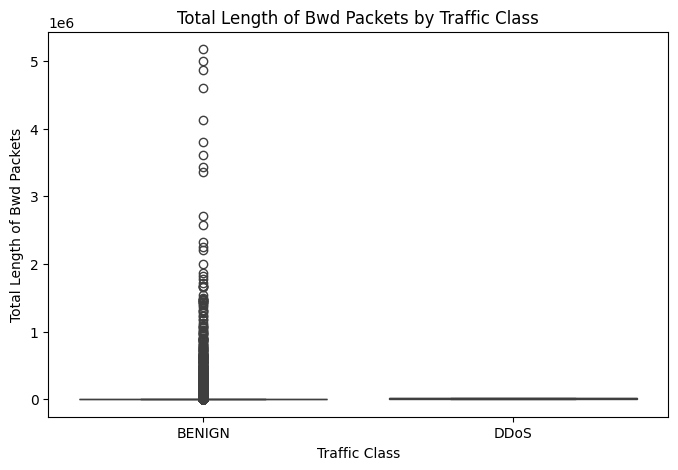

In [25]:
for feature in features_to_plot:

    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=df,
        x="Label",
        y=feature
    )

    plt.title(f"{feature} by Traffic Class")
    plt.xlabel("Traffic Class")
    plt.ylabel(feature)

    plt.show()

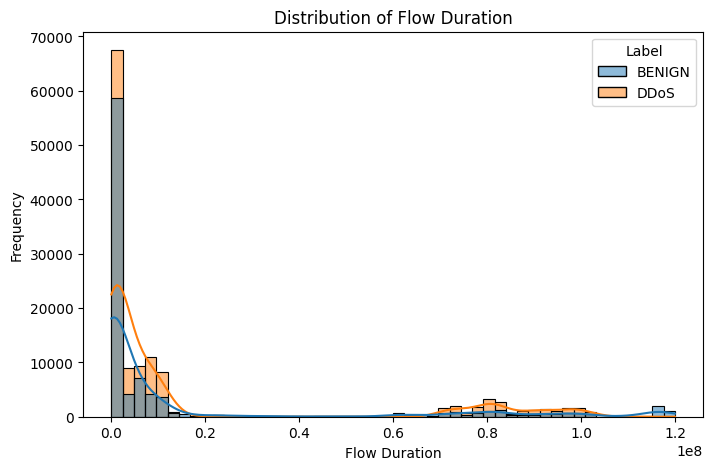

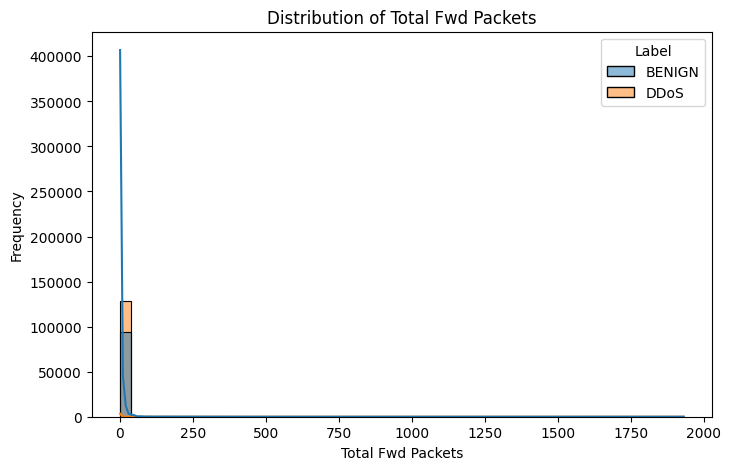

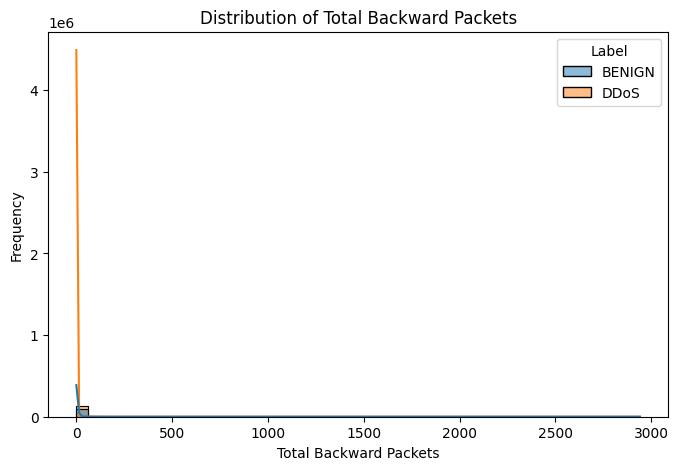

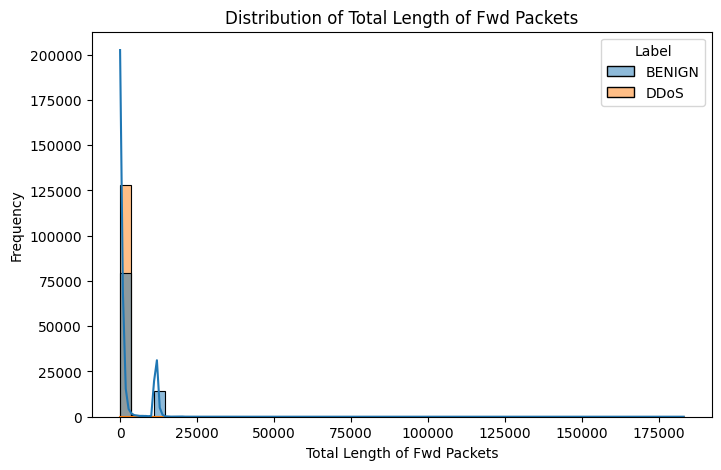

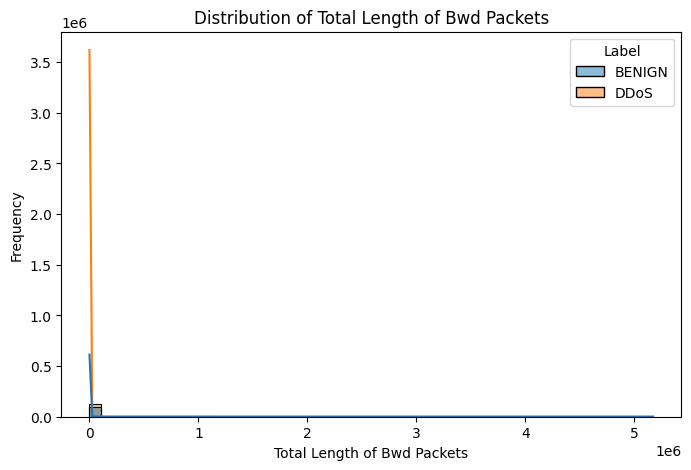

In [26]:
for feature in features_to_plot:

    plt.figure(figsize=(8, 5))

    sns.histplot(
        data=df,
        x=feature,
        hue="Label",
        kde=True,
        bins=50
    )

    plt.title(f"Distribution of {feature}")
    plt.xlabel(feature)
    plt.ylabel("Frequency")

    plt.show()

In [27]:
skewness = df[numeric_columns].skew()

skewness.sort_values(
    key=abs,
    ascending=False
).head(20)

ECE Flag Count                 90.881282
RST Flag Count                 90.881282
act_data_pkt_fwd               78.858377
Active Std                     77.083067
Flow Bytes/s                   73.890172
Total Length of Bwd Packets    69.207741
Subflow Bwd Bytes              69.207741
Subflow Bwd Packets            65.844072
Total Backward Packets         65.844072
Subflow Fwd Packets            59.323048
Total Fwd Packets              59.323048
Bwd Packets/s                  56.168863
Bwd Header Length              55.961522
Flow IAT Min                   55.592581
Fwd Header Length              54.122053
Fwd Header Length.1            54.122053
FIN Flag Count                 24.902691
Fwd IAT Min                    22.553450
Bwd IAT Min                    20.649936
Active Min                     15.358481
dtype: float64

In [28]:
highly_skewed = skewness[abs(skewness) > 2]

print("Number of highly skewed features:", len(highly_skewed))

Number of highly skewed features: 54


In [29]:
correlation_matrix = df[numeric_columns].corr()

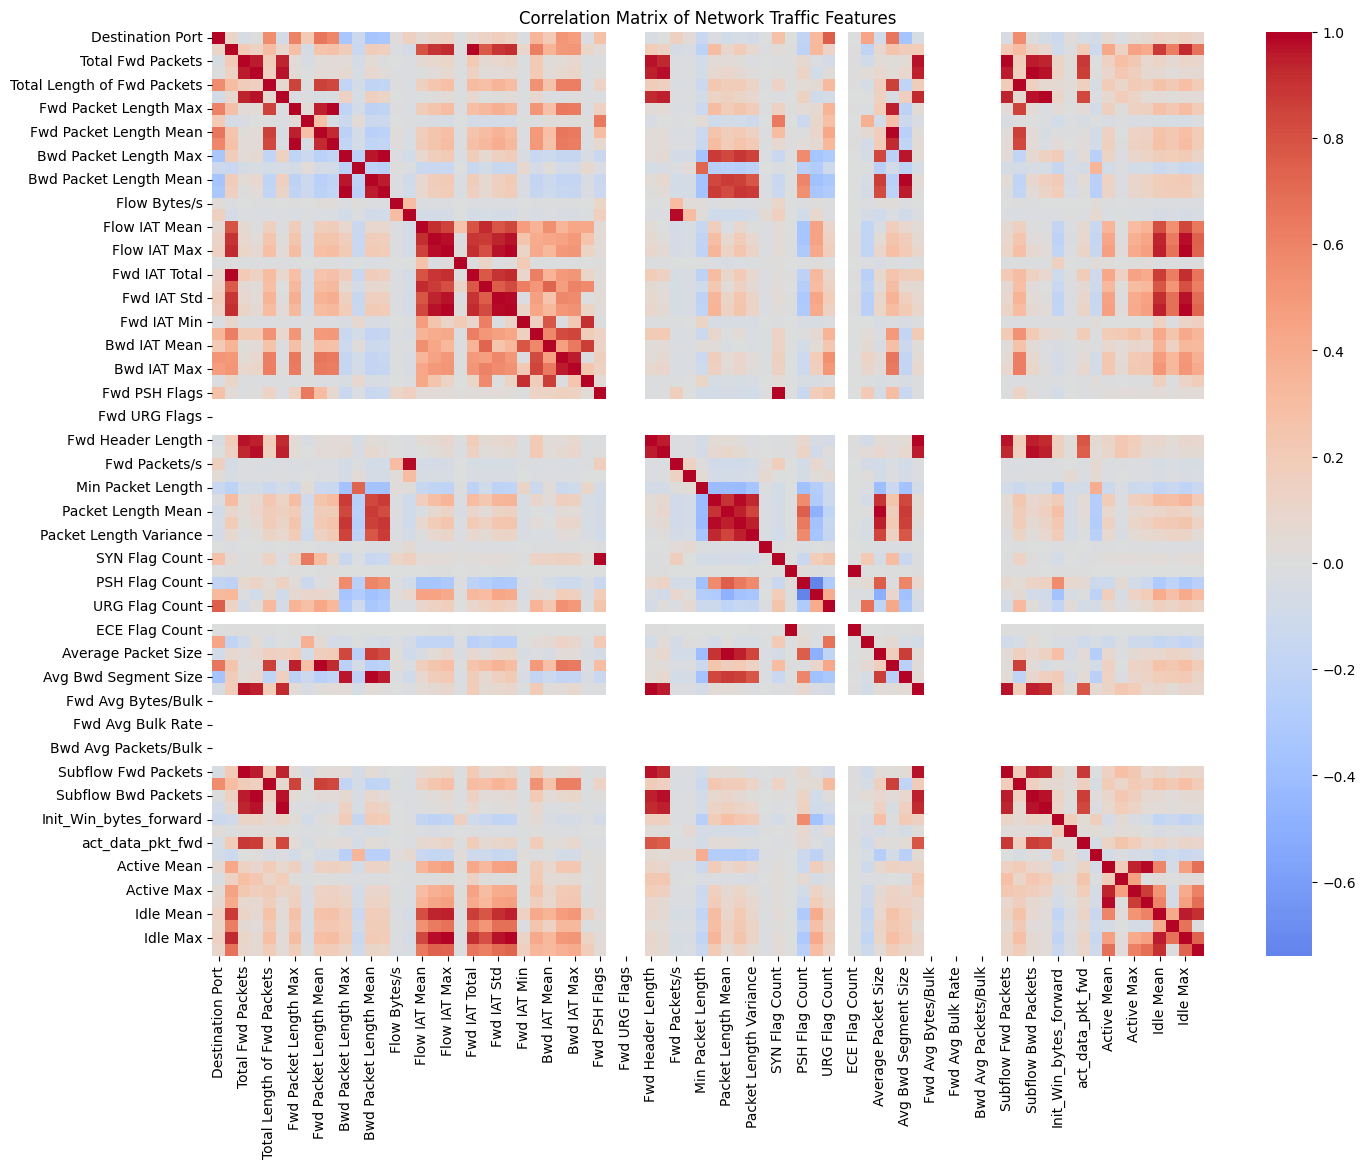

In [30]:
plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix of Network Traffic Features")

plt.show()

They contain very similar information.

This can indicate feature redundancy.

In [31]:
corr_pairs = (
    correlation_matrix
    .where(np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool))
    .stack()
    .sort_values(key=abs, ascending=False)
)

corr_pairs.head(20)

Bwd Packet Length Mean       Avg Bwd Segment Size     1.000000
Fwd Header Length            Fwd Header Length.1      1.000000
Total Backward Packets       Subflow Bwd Packets      1.000000
RST Flag Count               ECE Flag Count           1.000000
Total Fwd Packets            Subflow Fwd Packets      1.000000
Fwd PSH Flags                SYN Flag Count           1.000000
Total Length of Bwd Packets  Subflow Bwd Bytes        1.000000
Fwd Packet Length Mean       Avg Fwd Segment Size     1.000000
Total Length of Fwd Packets  Subflow Fwd Bytes        1.000000
Packet Length Mean           Average Packet Size      0.999354
Flow IAT Max                 Idle Max                 0.997261
Flow Duration                Fwd IAT Total            0.997050
Flow IAT Max                 Fwd IAT Max              0.995271
Fwd IAT Max                  Idle Max                 0.992974
Bwd Packet Length Max        Bwd Packet Length Std    0.992641
Fwd Packet Length Max        Fwd Packet Length Std    0

In [32]:
class_medians = df.groupby("Label")[numeric_columns].median().T

class_medians.head(20)


Label,BENIGN,DDoS
Destination Port,443.000000,8.000000e+01
Flow Duration,217393.500000,1.879122e+06
Total Fwd Packets,2.000000,4.000000e+00
Total Backward Packets,2.000000,4.000000e+00
Total Length of Fwd Packets,70.000000,2.600000e+01
Total Length of Bwd Packets,62.000000,1.160100e+04
Fwd Packet Length Max,42.000000,2.000000e+01
Fwd Packet Length Min,6.000000,0.000000e+00
Fwd Packet Length Mean,38.770979,7.000000e+00
Fwd Packet Length Std,0.000000,5.656854e+00


In [33]:
median_difference = (
    class_medians["DDoS"] -
    class_medians["BENIGN"]
).sort_values(key=abs, ascending=False)

median_difference.head(20)

Packet Length Variance         3.624028e+06
Fwd IAT Total                  1.764942e+06
Fwd IAT Max                    1.762986e+06
Flow IAT Max                   1.705504e+06
Flow Duration                  1.661728e+06
Fwd IAT Std                    9.324904e+05
Flow IAT Std                   8.849646e+05
Fwd IAT Mean                   4.906215e+05
Flow IAT Mean                  4.226706e+05
Bwd IAT Total                  7.472100e+04
Bwd IAT Max                    6.751150e+04
Bwd IAT Std                    3.328025e+04
Bwd IAT Mean                   1.903500e+04
Total Length of Bwd Packets    1.153900e+04
Subflow Bwd Bytes              1.153900e+04
Bwd Packet Length Max          5.735000e+03
Max Packet Length              5.653000e+03
Bwd Packet Length Std          2.189773e+03
Avg Bwd Segment Size           1.921500e+03
Bwd Packet Length Mean         1.921500e+03
dtype: float64

In [34]:
eda_summary = pd.DataFrame({
    "Mean_BENIGN": class_means["BENIGN"],
    "Mean_DDoS": class_means["DDoS"],
    "Mean_Difference": mean_difference,
    "Median_BENIGN": class_medians["BENIGN"],
    "Median_DDoS": class_medians["DDoS"],
    "Median_Difference": median_difference,
    "Skewness": skewness
})

eda_summary.head(20)

,Mean_BENIGN,Mean_DDoS,Mean_Difference,Median_BENIGN,Median_DDoS,Median_Difference,Skewness
ACK Flag Count,4.550848e-01,0.546776,9.169135e-02,0.000000,1.000000,1.000000,-0.030809
Active Max,2.237046e+05,200813.772712,-2.289078e+04,0.000000,0.000000,0.000000,15.054057
Active Mean,1.684751e+05,200813.772712,3.233866e+04,0.000000,0.000000,0.000000,15.102581
Active Min,1.513640e+05,200813.772712,4.944977e+04,0.000000,0.000000,0.000000,15.358481
Active Std,3.071345e+04,0.000000,-3.071345e+04,0.000000,0.000000,0.000000,77.083067
Average Packet Size,2.550537e+02,822.678641,5.676250e+02,78.500000,897.615385,819.115385,0.506686
Avg Bwd Segment Size,1.184550e+02,1481.144388,1.362689e+03,13.000000,1934.500000,1921.500000,0.656811
Avg Fwd Segment Size,3.806901e+02,7.401404,-3.732887e+02,38.770979,7.000000,-31.770979,3.290031
Bwd Avg Bulk Rate,0.000000e+00,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000
Bwd Avg Bytes/Bulk,0.000000e+00,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000


In [35]:
eda_summary = eda_summary.sort_values(
    "Mean_Difference",
    key=abs,
    ascending=False
)

eda_summary.head(20)

,Mean_BENIGN,Mean_DDoS,Mean_Difference,Median_BENIGN,Median_DDoS,Median_Difference,Skewness
Bwd IAT Total,1.499048e+07,4.439602e+05,-1.454652e+07,49.000000,7.477000e+04,7.472100e+04,3.734430
Bwd IAT Max,1.025397e+07,4.395530e+05,-9.814419e+06,49.000000,6.756050e+04,6.751150e+04,4.329726
Fwd IAT Max,9.945939e+06,1.552835e+07,5.582413e+06,4.000000,1.762990e+06,1.762986e+06,2.075545
Flow IAT Max,1.070369e+07,1.583927e+07,5.135577e+06,171152.500000,1.876657e+06,1.705504e+06,2.062006
Idle Max,1.017190e+07,1.515565e+07,4.983755e+06,0.000000,0.000000e+00,0.000000e+00,2.060007
Idle Mean,8.370104e+06,1.198640e+07,3.616298e+06,0.000000,0.000000e+00,0.000000e+00,2.473128
Packet Length Variance,8.914607e+05,4.257760e+06,3.366299e+06,1045.333333,3.625074e+06,3.624028e+06,1.669902
Bwd IAT Std,3.529263e+06,2.187153e+05,-3.310547e+06,0.000000,3.328025e+04,3.328025e+04,4.470794
Idle Min,6.542617e+06,8.817186e+06,2.274569e+06,0.000000,0.000000e+00,0.000000e+00,3.367516
Fwd IAT Total,1.431717e+07,1.651822e+07,2.201053e+06,4.000000,1.764946e+06,1.764942e+06,1.938863


## Conclusion

The exploratory analysis provided an initial understanding of the
network traffic dataset.

The analysis showed:

1. The dataset contains BENIGN and DDoS network traffic.

2. The class distribution was examined to identify potential
   class imbalance.

3. Several network traffic features show different distributions
   between BENIGN and DDoS traffic.

4. Many network-flow features are highly skewed and contain
   extreme observations.

5. Correlation analysis identified groups of features that may
   contain redundant information.

6. Mean and median comparisons provide initial evidence that
   some features may be useful for distinguishing the two classes.

However, exploratory analysis alone is not sufficient to select
the final features.

Therefore,  next we  will perform statistical feature
analysis using statistical tests, effect sizes, mutual information,
and model-based feature importance.